# 2. Tri automatique des tickets par IA

**Objectif :** lire le message du client et proposer automatiquement l'équipe qui doit traiter le ticket, ainsi que son niveau d'urgence.

**Méthode choisie :** TF-IDF + régression logistique.
- **TF-IDF** transforme chaque message en un vecteur qui donne du poids aux mots (et morceaux de mots) caractéristiques : « facture », « livraison », « mot de passe »...
- **La régression logistique** apprend quels mots mènent à quelle équipe et donne une **probabilité** pour chaque équipe.

Ce modèle est simple, rapide à entraîner et **explicable** : on peut montrer à une équipe métier pourquoi un ticket a été orienté chez elle. C'est une bonne première étape avant d'envisager un grand modèle de langage.

**Évaluation réaliste :** le modèle apprend sur les 9 premiers mois et il est testé sur les 3 derniers, qu'il n'a jamais vus, comme s'il était mis en production.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analyse import charger_tickets
from modele_tri import SEUIL_CONFIANCE, decouper, entrainer, evaluer, predire

plt.rcParams.update({
    "figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 13, "axes.titleweight": "bold",
    "font.size": 11,
})
BLEU, ROUGE, GRIS = "#2563EB", "#DC2626", "#9CA3AF"
pd.set_option("display.precision", 3)

tickets = charger_tickets("../data/tickets_support.csv")

In [2]:
entrainement, test = decouper(tickets)
print(f"Apprentissage : {len(entrainement)} tickets (nov. 2025 - juil. 2026)")
print(f"Test          : {len(test)} tickets (août - oct. 2026)")

modeles = entrainer(tickets)
resultats = evaluer(modeles, test)
predictions = resultats["predictions"]

print(f"\nBonne équipe trouvée   : {resultats['precision_equipe']:.1%}")
print(f"Bonne priorité trouvée : {resultats['precision_priorite']:.1%}")

Apprentissage : 4517 tickets (nov. 2025 - juil. 2026)
Test          : 1483 tickets (août - oct. 2026)

Bonne équipe trouvée   : 90.8%
Bonne priorité trouvée : 80.5%


## Résultats par équipe

- **precision** : quand le modèle envoie un ticket à cette équipe, à quelle fréquence a-t-il raison ?
- **recall** : parmi les tickets de cette équipe, quelle part le modèle retrouve-t-il ?

In [3]:
print(resultats["rapport_equipe"])

                           precision    recall  f1-score   support

Administration des ventes      0.921     0.924     0.922       302
     Comptabilité clients      0.906     0.917     0.911       252
               Logistique      0.875     0.951     0.911       405
                      SAV      0.932     0.860     0.895       222
        Support technique      0.932     0.864     0.897       302

                 accuracy                          0.908      1483
                macro avg      0.913     0.903     0.907      1483
             weighted avg      0.910     0.908     0.908      1483



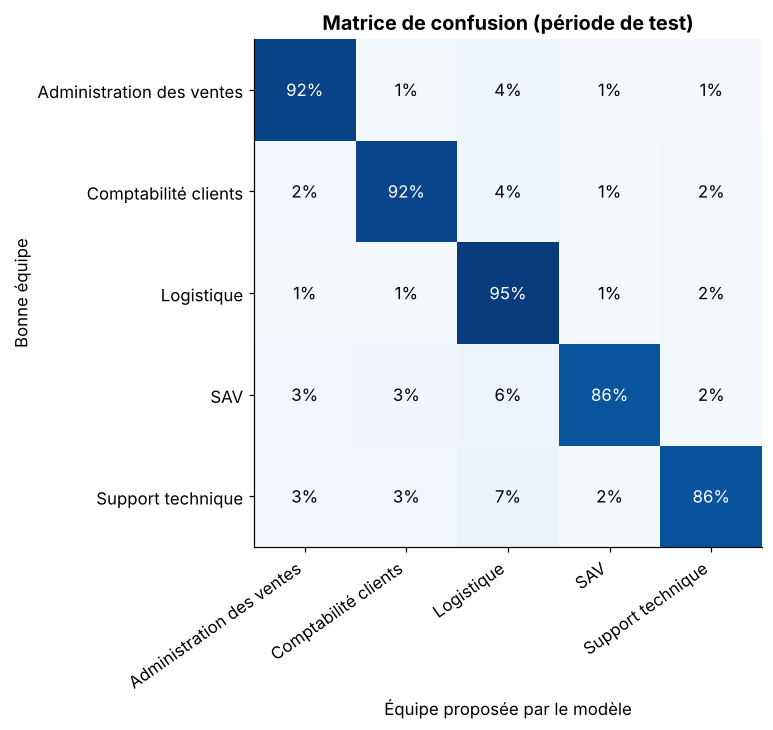

In [4]:
equipes = sorted(test["equipe_cible"].unique())
matrice = pd.crosstab(test["equipe_cible"], predictions["equipe_predite"], normalize="index").reindex(index=equipes, columns=equipes, fill_value=0)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(matrice.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(equipes)), equipes, rotation=35, ha="right")
ax.set_yticks(range(len(equipes)), equipes)
for i in range(len(equipes)):
    for j in range(len(equipes)):
        v = matrice.values[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.5 else "black")
ax.set_xlabel("Équipe proposée par le modèle")
ax.set_ylabel("Bonne équipe")
ax.set_title("Matrice de confusion (période de test)")
ax.grid(False)
plt.savefig("../reports/figures/matrice_confusion.png", dpi=130, bbox_inches="tight")

## Ne pas tout automatiser : le seuil de confiance

Certains messages sont trop vagues pour être triés de façon fiable (« pouvez-vous me rappeler au sujet de ma commande ? »). Plutôt que de risquer une erreur, **le modèle ne trie seul que les tickets pour lesquels il est suffisamment sûr**. Les autres restent lus par un agent.

Le graphique montre le compromis : plus le seuil est haut, moins on automatise, mais plus le tri automatique est fiable.

Avec un seuil de 60% : 87.7% des tickets triés automatiquement, avec 98.8% de bonnes orientations.


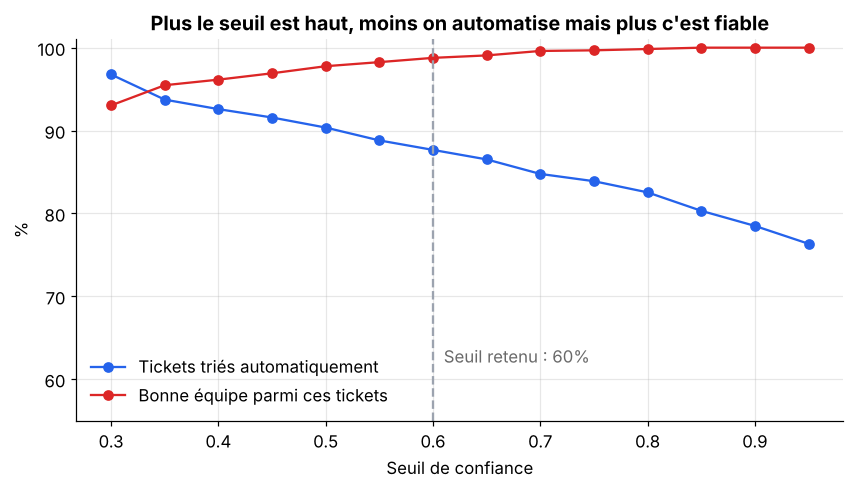

In [5]:
proba = modeles["equipe_cible"].predict_proba(test["message"])
confiance = proba.max(axis=1)
correct = modeles["equipe_cible"].classes_[proba.argmax(axis=1)] == test["equipe_cible"].values

seuils = np.arange(0.30, 0.96, 0.05)
part_auto = [(confiance >= s).mean() for s in seuils]
fiabilite = [correct[confiance >= s].mean() for s in seuils]

fig, ax = plt.subplots()
ax.plot(seuils, np.array(part_auto) * 100, marker="o", color=BLEU, label="Tickets triés automatiquement")
ax.plot(seuils, np.array(fiabilite) * 100, marker="o", color=ROUGE, label="Bonne équipe parmi ces tickets")
ax.axvline(SEUIL_CONFIANCE, color=GRIS, linestyle="--")
ax.text(SEUIL_CONFIANCE + 0.01, 62, f"Seuil retenu : {SEUIL_CONFIANCE:.0%}", color="dimgray")
ax.set_xlabel("Seuil de confiance")
ax.set_ylabel("%")
ax.set_ylim(55, 101)
ax.set_title("Plus le seuil est haut, moins on automatise mais plus c'est fiable")
ax.legend(frameon=False, loc="lower left")
plt.savefig("../reports/figures/seuil_confiance.png", dpi=130, bbox_inches="tight")

print(f"Avec un seuil de {SEUIL_CONFIANCE:.0%} : {resultats['part_tri_automatique']:.1%} des tickets triés automatiquement, "
      f"avec {resultats['precision_equipe_tri_auto']:.1%} de bonnes orientations.")

Avec un seuil de 60 %, **près de 9 tickets sur 10 sont triés automatiquement, avec moins de 2 % d'erreurs**, alors qu'aujourd'hui environ 16 % des tickets sont mal orientés. Les tickets laissés aux agents sont surtout les messages vagues ou qui mélangent plusieurs sujets.

## Pourquoi le modèle choisit une équipe

Les mots qui pèsent le plus pour chaque équipe permettent de vérifier que le modèle raisonne de façon logique. C'est utile pour le faire accepter par les équipes métier.

In [6]:
pipeline = modeles["equipe_cible"]
vocabulaire = pipeline.named_steps["texte"].transformer_list[0][1].get_feature_names_out()
nb_mots = len(vocabulaire)
coefficients = pipeline.named_steps["classifieur"].coef_[:, :nb_mots]

# On garde les mots simples et porteurs de sens (pas les mots de liaison)
mots_vides = {"bonjour", "pouvez", "vous", "nous", "notre", "votre", "merci", "pour", "avec", "dans", "mais",
              "plus", "sont", "avez", "ailleurs", "depuis", "toujours", "cette", "quel", "quelle", "faire"}
utiles = np.array([(" " not in m) and len(m) >= 4 and m not in mots_vides and not m.isdigit() for m in vocabulaire])

mots_cles = {}
for i, equipe in enumerate(pipeline.classes_):
    scores = np.where(utiles, coefficients[i], -np.inf)
    meilleurs = np.argsort(scores)[::-1][:8]
    mots_cles[equipe] = ", ".join(vocabulaire[meilleurs])
pd.Series(mots_cles, name="Mots les plus déterminants").to_frame()

,Mots les plus déterminants
Administration des ventes,"devis, ajouter, modifier, double, annuler, env..."
Comptabilité clients,"facture, avoir, mois, dernier, correspond, fac..."
Logistique,"livraison, retard, abime, livree, carton, tran..."
SAV,"appareil, panne, sous, garantie, retour, casse..."
Support technique,"portail, apres, aide, deploiement, sites, jour..."


## Exemples de tickets laissés à un agent

In [7]:
a_verifier = test.join(predictions).query("not tri_automatique")
pd.set_option("display.max_colwidth", 120)
a_verifier[["message", "equipe_cible", "equipe_predite", "confiance"]].head(6)

,message,equipe_cible,equipe_predite,confiance
4532,Pouvez-vous faire le point sur notre dossier en cours ?,Comptabilité clients,Logistique,0.464
4535,"Pouvez-vous nous donner une nouvelle date de livraison pour CMD-23079 ? Par ailleurs, la facture FAC-614543 ne corre...",Logistique,Comptabilité clients,0.505
4537,"Bonjour, pouvez-vous transmettre ma demande au bon service ? Rien de bloquant, c'est pour information. Bonne journée.",Logistique,Administration des ventes,0.293
4541,"Suite à notre échange téléphonique, je reviens vers vous concernant CMD-38741. Nous en avons besoin rapidement. Cord...",Administration des ventes,Logistique,0.307
4542,"Bonjour, pouvez-vous transmettre ma demande au bon service ? Merci de revenir vers nous avant la fin de semaine. Cor...",Logistique,Logistique,0.282
4545,Pouvez-vous faire le point sur notre dossier en cours ?,Support technique,Logistique,0.464


## Priorité du ticket

Le modèle prédit aussi l'urgence. Les tickets **urgents** sont très bien repérés, car les clients le disent explicitement. La distinction entre priorité **normale** et **basse** est plus difficile : beaucoup de clients ne précisent pas l'urgence. En pratique, la priorité proposée servirait d'aide à l'agent, pas de décision automatique.

In [8]:
print(resultats["rapport_priorite"])

              precision    recall  f1-score   support

       Basse      0.972     0.484     0.646       283
       Haute      0.867     0.676     0.759       327
     Normale      0.736     0.950     0.829       737
     Urgente      1.000     1.000     1.000       136

    accuracy                          0.805      1483
   macro avg      0.894     0.777     0.809      1483
weighted avg      0.834     0.805     0.795      1483



## À retenir

- **91 %** des tickets de test sont orientés vers la bonne équipe.
- Avec un seuil de confiance, **88 %** des tickets sont triés sans intervention humaine, avec **98,8 %** de bonnes orientations.
- Les cas ambigus restent traités par un agent : l'IA **assiste** le service client, elle ne le remplace pas.

**Limite importante :** les messages sont générés à partir de modèles de phrases, ils sont donc plus réguliers que de vrais messages clients. Sur de vraies données, il faudrait s'attendre à des performances plus basses et réentraîner le modèle régulièrement.

➡️ Le notebook 3 traduit ces résultats en **gains concrets** pour le service client.